In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
from retia_cognitionis.config import RAW_DATA_DIR, INTERIM_DATA_DIR
from nilearn import image
import nibabel as nib
import nilearn
from nilearn import datasets, plotting, maskers,masking
RAW = RAW_DATA_DIR / "ds000030/sub-10325/func"
img = nib.load(RAW/ "sub-10325_task-rest_bold.nii.gz")
fmri_data_one_subject = image.load_img(img)


In [2]:
print(fmri_data_one_subject)


<class 'nibabel.nifti1.Nifti1Image'>
data shape (64, 64, 34, 152)
affine:
[[ -3.           0.          -0.          87.67071533]
 [ -0.           2.57150197  -2.06015229 -55.50102997]
 [  0.           1.54511428   3.42866921 -80.8682251 ]
 [  0.           0.           0.           1.        ]]
metadata:
<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 1301201152
session_error   : 32767
regular         : b'r'
dim_info        : 57
dim             : [  4  64  64  34 152   0   0   0]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : int16
bitpix          : 16
slice_start     : 0
pixdim          : [-1.  3.  3.  4.  2.  0.  0.  0.]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : alternating increasing 2
xyzt_units      : 10
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0


Shape: (64, 64, 34) at time index 100



/tmp/ipykernel_136403/2703457456.py:6: UserWarning: Casting data from int32 to float32
  plotting.view_img(vol_brain,  threshold=1, symmetric_cmap=False, cmap="Reds", black_bg=True)



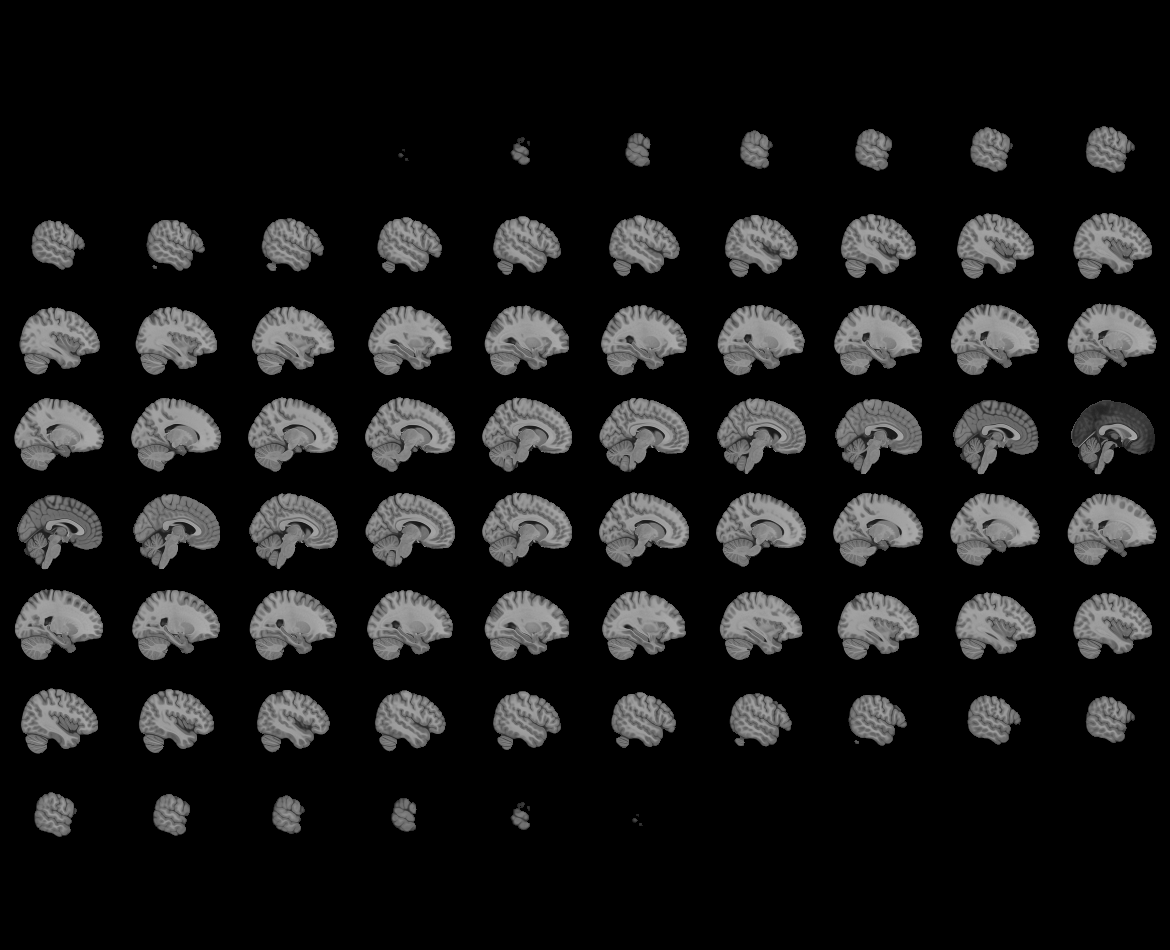
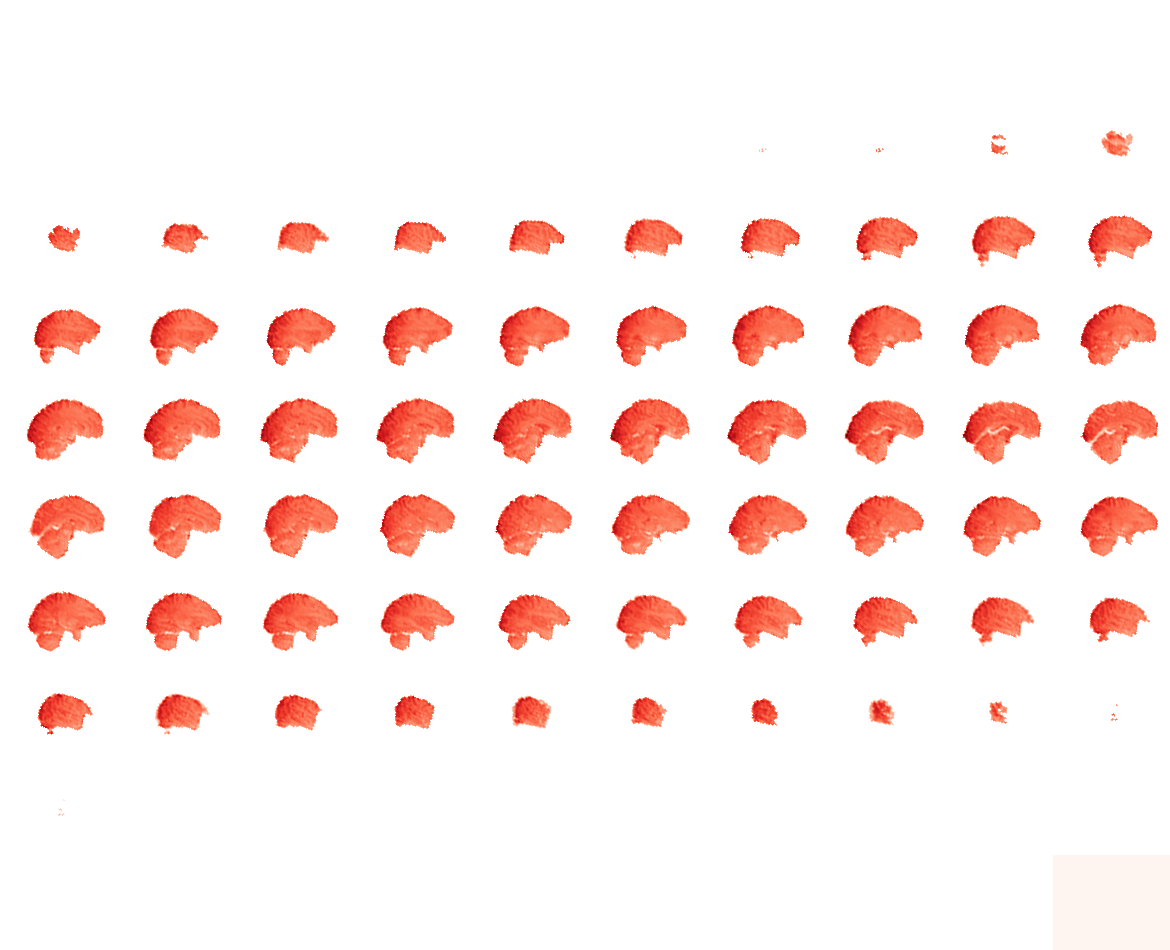

In [11]:
idx_time_point = 100
fmri_one_subject_one_time_pt = img.slicer[:,:,:,idx_time_point]
print(f"Shape: {fmri_one_subject_one_time_pt.shape} at time index {idx_time_point}\n")
brain_mask = masking.compute_epi_mask(img)   # คำนวณ mask จากข้อมูลทั้ง 4D
vol_brain = image.math_img("v * m", v=fmri_one_subject_one_time_pt, m=brain_mask)
plotting.view_img(vol_brain,  threshold=1, symmetric_cmap=False, cmap="Reds", black_bg=True)
